# SHARP final-geometry RGBD point cloud — CrowdPose 107292

This notebook makes an RGBD point cloud from a **depth raster derived from
SHARP's final Gaussian positions**. Rotate the interactive scene and
person-box views below. The [SHARP pilot](sharp-feasibility.md) records the
inference and final Gaussian PLY.

SHARP does not expose a distinct dense "refined depth map" after Gaussian
prediction. Its first depth layer is an intermediate visible-surface estimate;
the Gaussian decoder then refines 3D positions. Here we project **all** final
Gaussian centers into the source camera, keep centers with opacity at least
`0.5`, and take the nearest center at each pixel. This yields a **sparse
center-depth z-buffer**, not SHARP's official rendered depth: Gaussian size,
shape, and alpha compositing are omitted. We pair each valid depth pixel with
its source RGB pixel, then back-project with the same intrinsics. The raw first
layer is shown beside it for context.

The source CrowdPose JPEG lacks focal-length EXIF. SHARP used its documented
30 mm equivalent fallback, giving `f = 531.9 px` at `640×423`. Its
preprocessing stretches the image to `1536×1536`, so we scale `fx` and `fy`
separately. These coordinates are model-estimated meters under that camera
assumption. This notebook reads saved CPU inference arrays and does not load
SHARP or allocate CUDA memory.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "reports/3d-prior/assets/107292_sharp_depth.npz").exists():
    ROOT = Path.cwd().parents[1]
ASSETS = ROOT / "reports/3d-prior/assets"
IMAGE_ID = 107292
MAX_DISPLAY_DEPTH_M = 12.0
POINT_STRIDE = 4
assert (ASSETS / f"{IMAGE_ID}_sharp_depth.npz").exists(), "Run from the repository root or this notebook's directory"
assert (ASSETS / f"{IMAGE_ID}_sharp_all_centers.npz").exists(), "Run the SHARP pilot with --save-all-centers first"

with np.load(ASSETS / f"{IMAGE_ID}_sharp_depth.npz") as saved:
    depth_layers_m = saved["depth_m"]
    rgb = saved["rgb"]
    focal_px = float(saved["focal_px"])
    original_height, original_width = map(int, saved["original_hw"])

height, width = rgb.shape[:2]
assert rgb.shape == (1536, 1536, 3)
assert depth_layers_m.shape == (2, height, width)
assert np.isfinite(depth_layers_m).all() and (depth_layers_m > 0).all()
depth_m = depth_layers_m[0]

fx = focal_px * width / original_width
fy = focal_px * height / original_height
cx, cy = width / 2, height / 2
K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float32)
assert not np.isclose(fx, fy), "The original image is not square; focal scaling must differ by axis"
print("RGBD shape:", rgb.shape, "| first depth layer:", depth_m.shape)
print("Assumed original focal:", round(focal_px, 2), "px | processed K:", K)
print("Depth range:", round(float(depth_m.min()), 2), "to", round(float(depth_m.max()), 2), "m")


RGBD shape: (1536, 1536, 3) | first depth layer: (1536, 1536)
Assumed original focal: 531.93 px | processed K: [[1.2766255e+03 0.0000000e+00 7.6800000e+02]
 [0.0000000e+00 1.9315375e+03 7.6800000e+02]
 [0.0000000e+00 0.0000000e+00 1.0000000e+00]]
Depth range: 1.28 to 8311.36 m


## Camera projection and the derived depth raster

SHARP's Gaussian centers are already in OpenCV camera coordinates (`x` right,
`y` down, `z` forward). We project each center with the resized-image `K`,
keep only centers with opacity at least `0.5`, and use the nearest positive `z`
per pixel. Empty pixels stay empty; we do not interpolate or backfill them
from the intermediate depth map. The source RGB pixel supplies color.

For a valid pixel `(u,v,z)`, back-projection is
`((u-cx)z/fx, (v-cy)z/fy, z)`. The notebook verifies the inverse projection.
Display and PLY exports retain `z < 12 m` so distant sky does not dominate
the axes. The original Gaussian centers and intermediate depth arrays remain
unchanged. The person view selects pixels inside annotated boxes; these boxes
also include background.


In [2]:
def backproject(rgb_image, depth_image, intrinsics, stride, max_depth_m, pixel_mask=None):
    if rgb_image.shape[:2] != depth_image.shape:
        raise ValueError("RGB and depth dimensions must match")
    if pixel_mask is not None and pixel_mask.shape != depth_image.shape:
        raise ValueError("Pixel mask must match the depth image")
    rows = np.arange(0, depth_image.shape[0], stride)
    cols = np.arange(0, depth_image.shape[1], stride)
    pixel_u, pixel_v = np.meshgrid(cols, rows)
    sampled_depth = depth_image[::stride, ::stride]
    sampled_rgb = rgb_image[::stride, ::stride]
    valid = np.isfinite(sampled_depth) & (sampled_depth > 0) & (sampled_depth < max_depth_m)
    if pixel_mask is not None:
        valid &= pixel_mask[::stride, ::stride]
    z = sampled_depth[valid].astype(np.float32)
    x = (pixel_u[valid] - intrinsics[0, 2]) * z / intrinsics[0, 0]
    y = (pixel_v[valid] - intrinsics[1, 2]) * z / intrinsics[1, 1]
    points = np.column_stack((x, y, z)).astype(np.float32)
    colors = sampled_rgb[valid].astype(np.uint8)
    pixels = np.column_stack((pixel_u[valid], pixel_v[valid])).astype(np.float32)
    return points, colors, pixels

annotations = json.loads((ROOT / "data/crowdpose/annotations/crowdpose_val.json").read_text())
boxes = [a["bbox"] for a in annotations["annotations"]
         if a["image_id"] == IMAGE_ID and not a["iscrowd"]]
assert len(boxes) == 3
person_box_mask = np.zeros((height, width), dtype=bool)
for x, y, box_width, box_height in boxes:
    left = max(0, int(np.floor(x * width / original_width)))
    top = max(0, int(np.floor(y * height / original_height)))
    right = min(width, int(np.ceil((x + box_width) * width / original_width)))
    bottom = min(height, int(np.ceil((y + box_height) * height / original_height)))
    person_box_mask[top:bottom, left:right] = True

with np.load(ASSETS / f"{IMAGE_ID}_sharp_all_centers.npz") as saved_centers:
    centers_m = saved_centers["xyz_m"]
    center_opacity = saved_centers["opacity"]
    center_K = saved_centers["intrinsics"]
np.testing.assert_allclose(center_K, K, rtol=1e-5, atol=1e-3)
assert centers_m.ndim == 2 and centers_m.shape[1] == 3
assert center_opacity.shape == (len(centers_m),)

z = centers_m[:, 2]
valid_centers = np.isfinite(centers_m).all(axis=1) & (z > 0)
valid_centers &= np.isfinite(center_opacity) & (center_opacity >= 0.5)
projected_u = K[0, 0] * centers_m[valid_centers, 0] / z[valid_centers] + K[0, 2]
projected_v = K[1, 1] * centers_m[valid_centers, 1] / z[valid_centers] + K[1, 2]
center_z = z[valid_centers]
pixel_u = np.rint(projected_u).astype(np.int32)
pixel_v = np.rint(projected_v).astype(np.int32)
inside_image = (pixel_u >= 0) & (pixel_u < width) & (pixel_v >= 0) & (pixel_v < height)
flat_index = pixel_v[inside_image] * width + pixel_u[inside_image]
nearest_depth = np.full(height * width, np.inf, dtype=np.float32)
np.minimum.at(nearest_depth, flat_index, center_z[inside_image])
refined_center_depth_m = nearest_depth.reshape(height, width)
refined_center_depth_m[~np.isfinite(refined_center_depth_m)] = np.nan

scene_points, scene_colors, scene_pixels = backproject(
    rgb, refined_center_depth_m, K, POINT_STRIDE, MAX_DISPLAY_DEPTH_M
)
people_points, people_colors, people_pixels = backproject(
    rgb, refined_center_depth_m, K, POINT_STRIDE, MAX_DISPLAY_DEPTH_M,
    person_box_mask,
)
assert len(scene_points) and len(people_points)
reprojected = np.column_stack((
    K[0, 0] * scene_points[:, 0] / scene_points[:, 2] + K[0, 2],
    K[1, 1] * scene_points[:, 1] / scene_points[:, 2] + K[1, 2],
))
projection_error_px = float(np.max(np.abs(reprojected - scene_pixels)))
assert projection_error_px < 1e-3
print(f"Final Gaussian centers: {len(centers_m):,}; retained after opacity filter: {valid_centers.sum():,}")
print(f"Center-depth z-buffer coverage: {np.isfinite(refined_center_depth_m).mean():.1%} of processed pixels")
print(f"RGBD point cloud: {len(scene_points):,} points; inside person boxes: {len(people_points):,}")
print(f"Projection round-trip maximum error: {projection_error_px:.6f} px")


Final Gaussian centers: 1,179,648; retained after opacity filter: 1,099,399
Center-depth z-buffer coverage: 37.4% of processed pixels
RGBD point cloud: 17,950 points; inside person boxes: 5,817
Projection round-trip maximum error: 0.000061 px


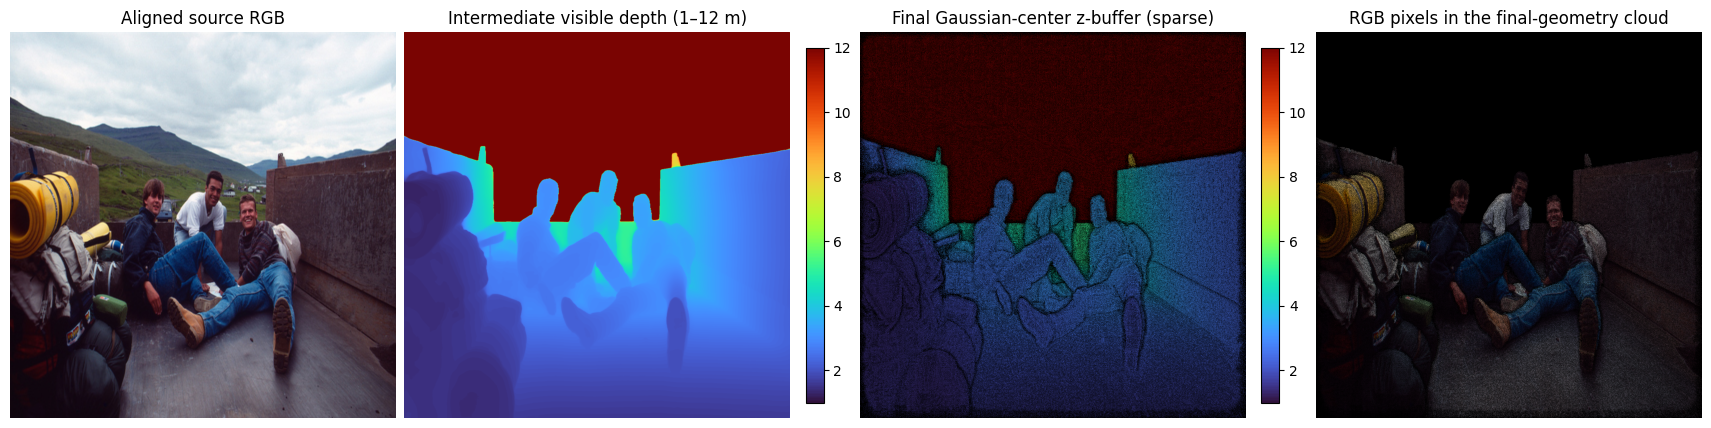

In [3]:
figure, axes = plt.subplots(1, 4, figsize=(17, 4.5), constrained_layout=True)
axes[0].imshow(rgb)
axes[0].set_title("Aligned source RGB")
raw_depth_artist = axes[1].imshow(depth_m, cmap="turbo", vmin=1, vmax=MAX_DISPLAY_DEPTH_M)
axes[1].set_title("Intermediate visible depth (1–12 m)")
figure.colorbar(raw_depth_artist, ax=axes[1], fraction=0.046, pad=0.04)
masked_depth = np.ma.masked_invalid(refined_center_depth_m)
center_cmap = plt.get_cmap("turbo").copy()
center_cmap.set_bad("black")
center_depth_artist = axes[2].imshow(masked_depth, cmap=center_cmap,
                                     vmin=1, vmax=MAX_DISPLAY_DEPTH_M)
axes[2].set_title("Final Gaussian-center z-buffer (sparse)")
figure.colorbar(center_depth_artist, ax=axes[2], fraction=0.046, pad=0.04)
valid_display = np.isfinite(refined_center_depth_m) & (refined_center_depth_m > 0)
valid_display &= refined_center_depth_m < MAX_DISPLAY_DEPTH_M
axes[3].imshow(np.where(valid_display[..., None], rgb, 0))
axes[3].set_title("RGB pixels in the final-geometry cloud")
for axis in axes:
    axis.axis("off")
figure_path = ASSETS / f"{IMAGE_ID}_sharp_refined_rgbd_overview.png"
figure.savefig(figure_path, dpi=150)
display(figure)
plt.close(figure)


## Fixed 3D views

These orthographic plots show depth separation without needing to rotate the
viewer. They contain the same RGB points selected by the annotated person
boxes, including any background inside those boxes.


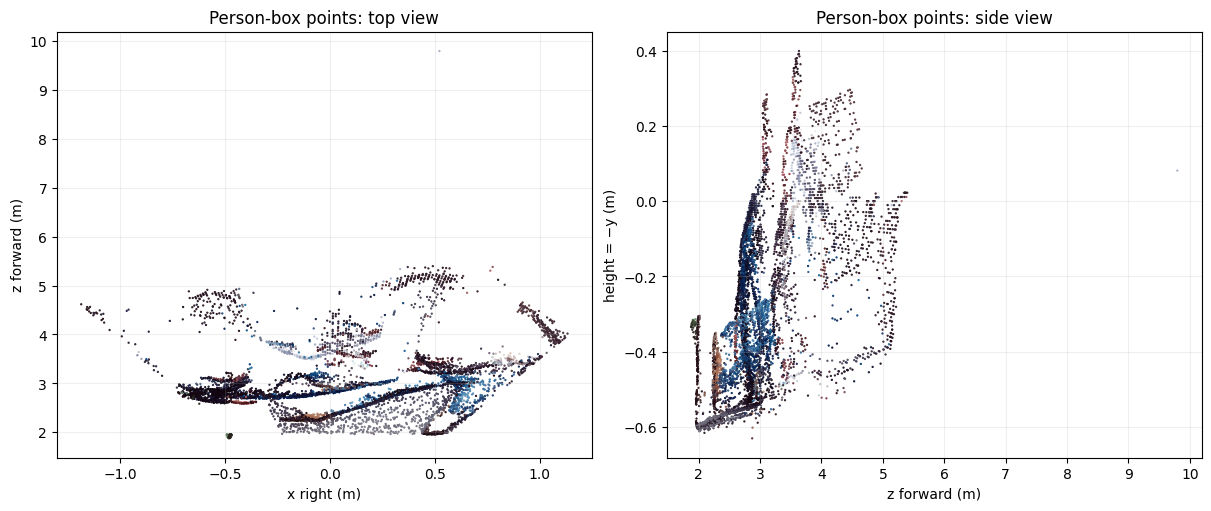

In [4]:
# Fixed orthographic views help reveal depth separation without rotating Plotly.
figure, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
plot_colors = people_colors.astype(np.float32) / 255.0
axes[0].scatter(people_points[:, 0], people_points[:, 2], s=0.4,
                c=plot_colors, rasterized=True)
axes[0].set(xlabel="x right (m)", ylabel="z forward (m)",
            title="Person-box points: top view")
axes[1].scatter(people_points[:, 2], -people_points[:, 1], s=0.4,
                c=plot_colors, rasterized=True)
axes[1].set(xlabel="z forward (m)", ylabel="height = −y (m)",
            title="Person-box points: side view")
for axis in axes:
    axis.grid(alpha=0.2)
figure_path = ASSETS / f"{IMAGE_ID}_sharp_refined_rgbd_orthographic.png"
figure.savefig(figure_path, dpi=160)
display(figure)
plt.close(figure)


## Interactive RGBD point clouds

Drag to rotate; scroll to zoom. The points below come from the **derived
final Gaussian-center depth z-buffer** paired with source RGB. They are
separate from the direct Gaussian-center PLY in the earlier pilot. The first
view is the foreground scene; the second selects pixels within the three
CrowdPose person boxes. Both are also saved as standalone HTML and RGB PLY.


In [5]:
def point_cloud_figure(points, colors, title, maximum_viewer_points=45_000):
    indices = np.linspace(0, len(points) - 1,
                          min(len(points), maximum_viewer_points)).astype(int)
    shown_points = points[indices]
    shown_colors = colors[indices]
    color_strings = [f"rgb({red},{green},{blue})" for red, green, blue in shown_colors]
    figure = go.Figure(go.Scatter3d(
        x=shown_points[:, 0], y=shown_points[:, 1], z=shown_points[:, 2],
        mode="markers", marker=dict(size=1.7, color=color_strings, opacity=0.95),
        hovertemplate="x=%{x:.2f} m<br>y=%{y:.2f} m<br>z=%{z:.2f} m<extra></extra>",
    ))
    figure.update_layout(
        title=f"{title} ({len(shown_points):,} displayed RGB points)",
        width=980, height=650, margin=dict(l=0, r=0, t=55, b=0),
        scene=dict(
            xaxis_title="x right (m)", yaxis_title="y down (m)",
            zaxis_title="z forward (m)", aspectmode="data",
            camera=dict(eye=dict(x=1.3, y=-0.65, z=-1.35)),
        ),
    )
    return figure

scene_figure = point_cloud_figure(scene_points, scene_colors, "SHARP final-geometry RGBD scene")
scene_html = ASSETS / f"{IMAGE_ID}_sharp_refined_rgbd_scene.html"
scene_figure.write_html(scene_html, include_plotlyjs=True)
display(scene_figure)


In [6]:
people_figure = point_cloud_figure(people_points, people_colors,
                                   "SHARP final-geometry RGBD in person boxes")
people_html = ASSETS / f"{IMAGE_ID}_sharp_refined_rgbd_people.html"
people_figure.write_html(people_html, include_plotlyjs=True)
display(people_figure)


In [7]:
def write_binary_rgb_ply(path, points, colors):
    vertex_dtype = np.dtype([
        ("x", "<f4"), ("y", "<f4"), ("z", "<f4"),
        ("red", "u1"), ("green", "u1"), ("blue", "u1"),
    ])
    vertices = np.empty(len(points), dtype=vertex_dtype)
    for dimension, name in enumerate(("x", "y", "z")):
        vertices[name] = points[:, dimension]
    for channel, name in enumerate(("red", "green", "blue")):
        vertices[name] = colors[:, channel]
    header = ("ply\nformat binary_little_endian 1.0\n"
              f"element vertex {len(vertices)}\n"
              "property float x\nproperty float y\nproperty float z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\n"
              "end_header\n")
    with Path(path).open("wb") as output:
        output.write(header.encode("ascii"))
        vertices.tofile(output)

scene_ply = ASSETS / f"{IMAGE_ID}_sharp_refined_rgbd_scene.ply"
people_ply = ASSETS / f"{IMAGE_ID}_sharp_refined_rgbd_people.ply"
write_binary_rgb_ply(scene_ply, scene_points, scene_colors)
write_binary_rgb_ply(people_ply, people_points, people_colors)
print("Saved:", scene_html.name, people_html.name, scene_ply.name, people_ply.name)


Saved: 107292_sharp_refined_rgbd_scene.html 107292_sharp_refined_rgbd_people.html 107292_sharp_refined_rgbd_scene.ply 107292_sharp_refined_rgbd_people.ply


## Reading the result

This point cloud uses a sparse raster made from **final Gaussian centers**
whose 3D positions were refined by SHARP's Gaussian decoder. Color comes from
the aligned source image, so every exported point is an RGBD pixel. It is a
center-based diagnostic, not the depth image that SHARP's Gaussian renderer
would produce with full splat size and alpha compositing. The intermediate
first depth layer is displayed above for comparison.

Rotating away from the source view reveals whether the final positions form
useful geometry. The person-box subset is easier to inspect, but boxes include
background and cannot recover occluded body parts.

- [RGBD overview](assets/107292_sharp_refined_rgbd_overview.png) / [fixed top and side views](assets/107292_sharp_refined_rgbd_orthographic.png)
- [Interactive refined scene cloud](assets/107292_sharp_refined_rgbd_scene.html) / [scene RGB PLY](assets/107292_sharp_refined_rgbd_scene.ply)
- [Interactive person-box cloud](assets/107292_sharp_refined_rgbd_people.html) / [person-box RGB PLY](assets/107292_sharp_refined_rgbd_people.ply)
- [Final Gaussian centers](assets/107292_sharp_all_centers.npz) / [intermediate depth and RGB](assets/107292_sharp_depth.npz)
